In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid')
print('Libraries loaded')

Libraries loaded


In [2]:
df = pd.read_csv("../../data/feature_engineering/data/daily_features_all.csv", parse_dates=["date"])
print(df.shape)
print(df["whale_id"].value_counts().sort_index())

(712, 37)
whale_id
W-1     78
W-2    300
W-3    139
W-4     27
W-5     35
W-6     88
W-7     45
Name: count, dtype: int64


shows how many days each whales appears in the dataset including days with no open position

In [3]:
panel = df.dropna(subset=["ltv", "carry_spread", "carry_spread_levered"]).copy()
print(len(panel), len(df))
print(panel["whale_id"].value_counts().sort_index())

457 712
whale_id
W-1     77
W-2     88
W-3    139
W-4     26
W-5     34
W-6     87
W-7      6
Name: count, dtype: int64


Drops rows with no `ltv` (a.k.a no open debt that day) and/or missing `carry_spread`/`carry_spread_levered`.
The new counts include only days we can actually cluster. The count for W-7 changes from 45 to 6 so the archetype percentage for W-7 will be unreliable.

In [9]:
FEATURES = [
    "ltv", "loop_depth", "distance_to_liq",
    "ltv_vol_7d", "ltv_vol_14d",
    "rebal_freq_7d", "rebal_freq_30d", "days_since_rebalance",
    "ltv_lag_7", "carry_spread", "carry_spread_levered",
]

X = panel[FEATURES].fillna(panel[FEATURES].median())
X.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
ltv,457.0,0.794,0.289,0.000,0.840,0.894,0.935,0.962
loop_depth,457.0,10.567,6.683,0.000,6.000,9.000,15.000,26.000
distance_to_liq,457.0,0.147,0.296,0.001,0.009,0.029,0.099,0.965
ltv_vol_7d,457.0,0.014,0.069,0.000,0.000,0.000,0.001,0.500
ltv_vol_14d,457.0,0.023,0.081,0.000,0.000,0.001,0.002,0.486
rebal_freq_7d,457.0,1.396,1.909,0.000,0.000,0.000,2.000,7.000
rebal_freq_30d,457.0,5.438,6.232,0.000,0.000,3.000,9.000,24.000
days_since_rebalance,457.0,20.589,25.449,0.000,1.000,7.000,35.000,97.000
ltv_lag_7,457.0,0.825,0.253,0.000,0.868,0.895,0.935,0.962
carry_spread,457.0,2.925,1.975,-5.767,2.713,3.377,3.895,8.292


The table above shows the stats for each 11 behavioural feature on those 457 days.

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pd.DataFrame(X_scaled, columns=FEATURES).describe().loc[["mean", "std"]].round(3)

,ltv,loop_depth,distance_to_liq,ltv_vol_7d,ltv_vol_14d,rebal_freq_7d,rebal_freq_30d,days_since_rebalance,ltv_lag_7,carry_spread,carry_spread_levered
mean,0.000,0.000,0.000,-0.000,-0.000,0.000,0.000,0.000,-0.000,0.000,0.000
std,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001


`StandardScaler` puts all 11 features on the same scale so HDBSCAN doesn't treat - for instance - `loop_depth` (0-26) as more important than `distance_to_liq` (0-1) just because the numbers are bigger.

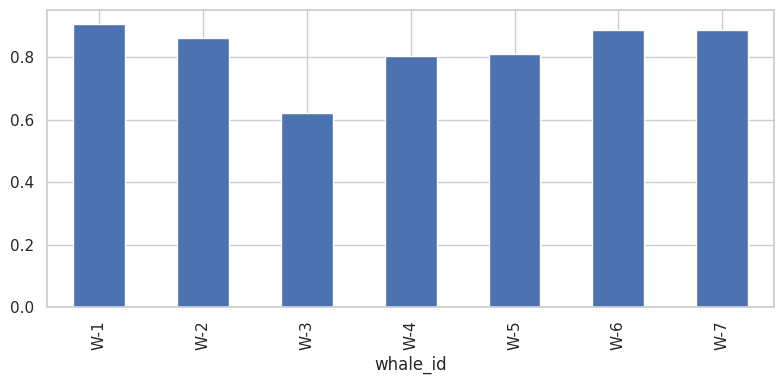

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
panel.groupby("whale_id")["ltv"].mean().sort_index().plot(kind="bar", ax=ax)
plt.tight_layout()
plt.show()

The plot above shows the mean LTV per whale only on the days with open debt positions. W-3 is shown as the least aggressive or more idle/mixed days. W-1 is shown with the highest leverage on average.

### Save features to CSV

In [7]:
panel[["whale_id", "protocol", "date"] + FEATURES].to_csv("panel_cluster_ready.csv", index=False)